# Quantum Neural Networks (QNN) - feature QNN and hybrid ResNet18 + quantum layer

Mirrors `qml/src/qnn_features.py`, `qml/src/qnn_hybrid.py` and `qml/src/qnn_compare.py`. This notebook does **not** re-run the full training (that takes ~25 min; see `docs/06_qnn.md` section 6.12). It:

1. checks that the QNN encoding is the VQC's,
2. draws the circuits,
3. reloads the saved QNN weights and reproduces the reported test metrics,
4. runs a few training epochs to show the loop,
5. reloads the saved hybrid head + quantum layer and reproduces its test result on the image patches (if they are available locally),
6. shows the comparison tables and graphs.

All quantum layers are exact classical simulations (PennyLane `default.qubit`). No quantum advantage is claimed.

In [1]:
import os, sys, json
os.environ['CUDA_VISIBLE_DEVICES'] = ''   # this notebook runs on the CPU only
from pathlib import Path
QML = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path('qml')
sys.path.insert(0, str(QML / 'src'))
import numpy as np, pandas as pd, torch, pennylane as qml
import qnn_features as QF
from evaluation import compute_metrics, METRICS_DIR, GRAPHS_DIR
torch.set_num_threads(4)
print('torch', torch.__version__, '| pennylane', qml.__version__)

torch 2.14.1+cu126 | pennylane 0.45.1


## 1. Same encoding as the VQC
The PennyLane-torch circuit with the VQC's ansatz must give the same ⟨Z⟩ values as the hand-written NumPy simulator in `quantum_model.py`.

In [2]:
QF.check_against_vqc()

max |PennyLane-torch - VQC NumPy simulator| = 3.33e-16
OK: the QNN uses the same encoding / wire conventions as the VQC.


## 2. Circuits (gate level)
`Rot(φ,θ,ω) = RZ(ω)·RY(θ)·RZ(φ)`; the CNOT range changes from layer to layer (StronglyEntanglingLayers).

In [3]:
QF.draw_circuits()
print((METRICS_DIR / 'qnn_circuits.txt').read_text(encoding='utf-8'))

wrote qml/results/metrics/qnn_circuits.txt
### Part A - QNN on the 8 feature angles (chosen: 2 layers, re-uploading off)

0: ──RY──RZ──Rot─╭●───────╭X──Rot─╭●────╭X────┤  <Z>
1: ──RY──RZ──Rot─╰X─╭●────│───Rot─│──╭●─│──╭X─┤  <Z>
2: ──RY──RZ──Rot────╰X─╭●─│───Rot─╰X─│──╰●─│──┤  <Z>
3: ──RY──RZ──Rot───────╰X─╰●──Rot────╰X────╰●─┤  <Z>

### Part A - same circuit with data re-uploading on (2 layers)

0: ──RY──RZ──Rot─╭●───────╭X──RY──RZ──Rot─╭●────╭X────┤  <Z>
1: ──RY──RZ──Rot─╰X─╭●────│───RY──RZ──Rot─│──╭●─│──╭X─┤  <Z>
2: ──RY──RZ──Rot────╰X─╭●─│───RY──RZ──Rot─╰X─│──╰●─│──┤  <Z>
3: ──RY──RZ──Rot───────╰X─╰●──RY──RZ──Rot────╰X────╰●─┤  <Z>

### Part B - quantum layer of the hybrid ResNet18 network (3 layers, re-uploading on, RY encoding)

0: ──RY──Rot─╭●───────╭X──RY──Rot─╭●────╭X──RY──Rot──────╭●─╭X───────┤  <Z>
1: ──RY──Rot─╰X─╭●────│───RY──Rot─│──╭●─│──╭X───RY───Rot─│──╰●─╭X────┤  <Z>
2: ──RY──Rot────╰X─╭●─│───RY──Rot─╰X─│──╰●─│────RY───Rot─│─────╰●─╭X─┤  <Z>
3: ──RY──Rot───────╰X─╰●──RY

## 3. Part A - reload the final QNN and reproduce its test metrics
Same 8 angles as the VQC/QSVM (StandardScaler → PCA(8) → [0, π], fitted on training data only).

In [4]:
d = QF.load_angles(QML / 'data' / 'features_cprd.csv')
w = json.loads((METRICS_DIR / 'qnn_features_weights.json').read_text())
model = QF.build_model('qnn', w['n_layers'], w['reupload'])
model.load_state_dict({k: torch.tensor(v) for k, v in w.items() if k not in ('n_layers', 'reupload')})
model.eval()
with torch.no_grad():
    pred = model(d['X_test']).argmax(1).numpy()
m = compute_metrics(d['y_test'].numpy(), pred)
saved = json.loads((METRICS_DIR / 'qnn_features.json').read_text())
print(f"reloaded: acc {m['accuracy']:.3f}  F1 {m['f1_macro']:.3f}   |  saved: acc {saved['accuracy']:.3f}  F1 {saved['f1_macro']:.3f}")
print('confusion matrix (rows = actual Cracks/Normal/Pothole):')
print(np.array(m['confusion_matrix']))
print('trainable parameters:', QF.n_params(model))

reloaded: acc 0.663  F1 0.662   |  saved: acc 0.663  F1 0.662
confusion matrix (rows = actual Cracks/Normal/Pothole):
[[59 19 22]
 [ 8 78 14]
 [27 11 62]]
trainable parameters: 39


## 4. The training loop in action (5 epochs, validation road stretches only)

In [5]:
torch.manual_seed(42)
demo = QF.build_model('qnn', 2, False)
res = QF.train(demo, d['X_train'][d['tr_idx']], d['y_train'][d['tr_idx']], d['X_train'][d['va_idx']], d['y_train'][d['va_idx']],
               lr=0.03, epochs=5, patience=99, verbose=False)
pd.DataFrame(res['history']).drop(columns='best', errors='ignore').round(3)

,epoch,train_loss,train_acc,train_f1,val_loss,val_acc,val_f1
0,1,1.049,0.541,0.537,1.047,0.592,0.587
1,2,0.982,0.573,0.565,0.991,0.564,0.558
2,3,0.928,0.603,0.596,0.941,0.564,0.563
3,4,0.901,0.589,0.590,0.893,0.592,0.591
4,5,0.870,0.616,0.613,0.872,0.583,0.580


## 5. Part A - hyper-parameter sweep (validation F1, test set unused)

In [6]:
sel = json.loads((METRICS_DIR / 'qnn_features_selection.json').read_text())
print('chosen:', sel['chosen_config'])
pd.DataFrame(sel['configs']).T[['kind', 'layers', 'reupload', 'lr', 'val_f1', 'best_epoch', 'n_params']].sort_values('val_f1', ascending=False)

chosen: {'layers': 2, 'reupload': False, 'lr': 0.03, 'epochs': 32, 'control_lr': 0.03, 'control_epochs': 22}


,kind,layers,reupload,lr,val_f1,best_epoch,n_params
"layers=2,reupload=off,lr=0.03",qnn,2,False,0.03,0.735009,32,39
"layers=4,reupload=off,lr=0.03",qnn,4,False,0.03,0.727455,57,63
"layers=2,reupload=off,lr=0.01",qnn,2,False,0.01,0.719577,47,39
"layers=4,reupload=off,lr=0.1",qnn,4,False,0.1,0.717677,5,63
"layers=2,reupload=on,lr=0.03",qnn,2,True,0.03,0.699629,38,39
"layers=3,reupload=off,lr=0.01",qnn,3,False,0.01,0.698506,38,51
"control,lr=0.03",control,0,False,0.03,0.697762,22,51
"layers=4,reupload=off,lr=0.01",qnn,4,False,0.01,0.697442,34,63
"layers=3,reupload=off,lr=0.03",qnn,3,False,0.03,0.69654,43,51
"layers=2,reupload=off,lr=0.1",qnn,2,False,0.1,0.69438,9,39


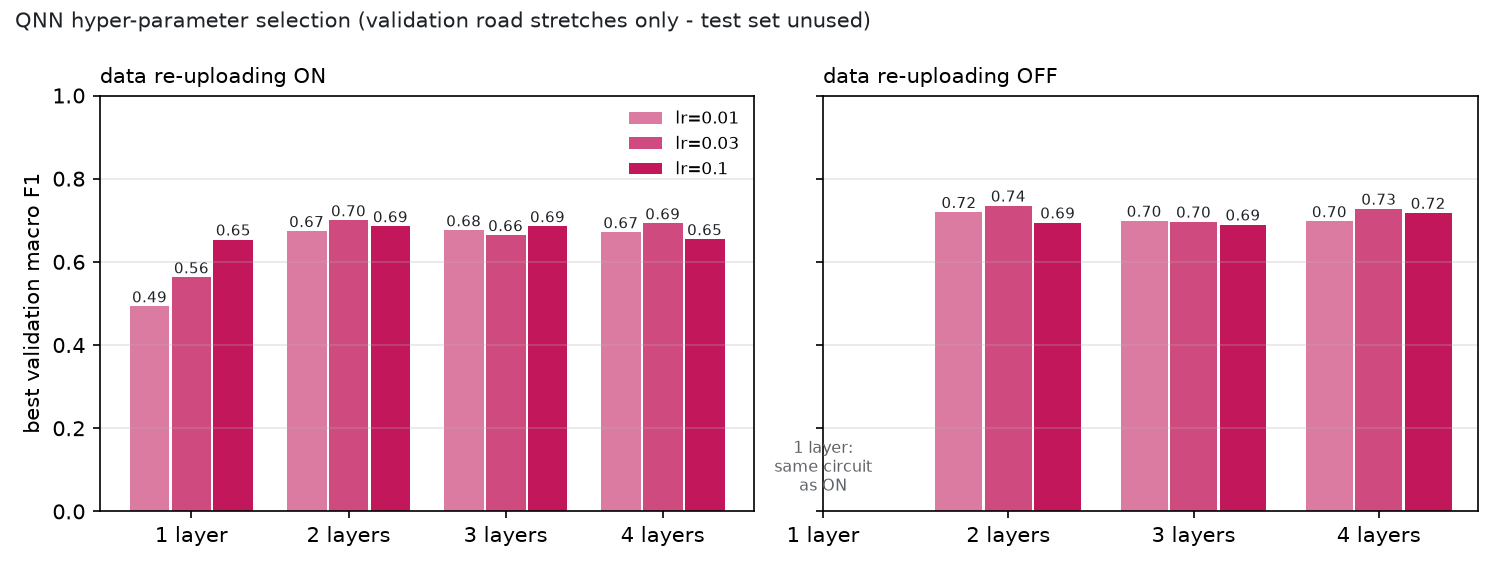

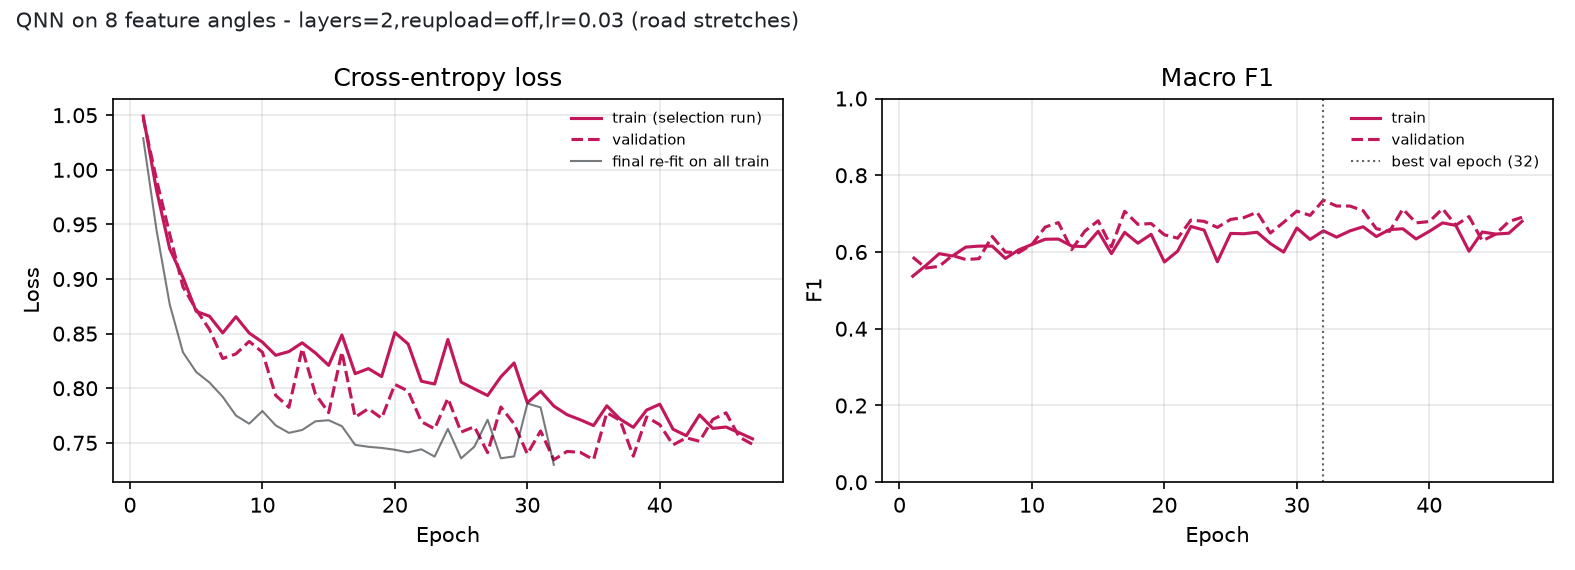

In [7]:
from IPython.display import Image, display
display(Image(str(GRAPHS_DIR / 'qnn_features_selection.png')))
display(Image(str(GRAPHS_DIR / 'qnn_features_training_curve.png')))

## 6. Part B - hybrid ResNet18 + quantum layer: reload the frozen-backbone model and reproduce its test result
Needs the image patches in `qml/data/patches/cprd/` (git-ignored) and the ImageNet ResNet18 weights (downloaded by torchvision). Runs on the CPU here, in float32, while the reported run used GPU fp16 for the backbone, so one or two predictions can differ.

In [8]:
import qnn_hybrid as QH
man = QML / 'data' / 'patches' / 'cprd' / 'manifest.csv'
if man.exists():
    data = QH.load_patches('cprd')
    bb = QH.make_backbone().eval()
    head = QH.make_head('quantum')
    sd = json.loads((METRICS_DIR / 'qnn_hybrid_frozen_quantum_weights.json').read_text())
    head.load_state_dict({k: torch.tensor(v) for k, v in sd.items()})
    with torch.no_grad():
        logits = QH.predict_images(bb, head, data['X'], data['test'], 'cpu')
    mh = compute_metrics(data['y'][data['test']].numpy(), logits.argmax(1).numpy())
    saved = json.loads((METRICS_DIR / 'qnn_hybrid_frozen_quantum.json').read_text())
    print(f"reloaded (CPU fp32): acc {mh['accuracy']:.3f} F1 {mh['f1_macro']:.3f}  |  saved (GPU fp16): acc {saved['accuracy']:.3f} F1 {saved['f1_macro']:.3f}")
    print(np.array(mh['confusion_matrix']))
else:
    print('image patches not available locally - skipped')

reloaded (CPU fp32): acc 0.817 F1 0.817  |  saved (GPU fp16): acc 0.817 F1 0.817
[[78 13  9]
 [14 83  3]
 [12  4 84]]


### Classical-control ablation (all hybrid runs)
The middle layer is the only difference: 4-qubit circuit (36 weights) vs `Linear(4,4)+tanh` ×2 (40 weights) vs nothing.

In [9]:
rows = []
for tag, split in (('qnn_hybrid', 'road stretches'), ('qnn_hybrid_unseen_highway', 'unseen highways')):
    for setting in ('frozen', 'finetune'):
        for mid in ('quantum', 'classical', 'identity'):
            p = METRICS_DIR / f'{tag}_{setting}_{mid}.json'
            if p.exists():
                m = json.loads(p.read_text())
                rows.append({'split': split, 'setting': setting, 'middle layer': mid, 'params (middle)': m['middle_params'],
                             'test F1 (seed 42)': round(m['f1_macro'], 3), 'F1 mean': round(m['f1_mean'], 3), 'F1 sd': round(m['f1_std'], 3),
                             'n seeds': len(m['seeds']), 'train s': round(m['train_time_s'], 1), 'peak VRAM MiB': round(m['peak_vram_mib'])})
pd.DataFrame(rows)

,split,setting,middle layer,params (middle),test F1 (seed 42),F1 mean,F1 sd,n seeds,train s,peak VRAM MiB
0,road stretches,frozen,quantum,36,0.817,0.807,0.016,5,45.7,358
1,road stretches,frozen,classical,40,0.808,0.787,0.064,5,3.7,358
2,road stretches,frozen,identity,0,0.774,0.749,0.086,5,3.7,358
3,road stretches,finetune,quantum,36,0.830,0.761,0.101,3,83.0,637
4,road stretches,finetune,classical,40,0.847,0.835,0.017,3,63.6,638
5,unseen highways,frozen,quantum,36,0.701,0.750,0.030,5,25.1,358
6,unseen highways,frozen,classical,40,0.763,0.773,0.034,5,5.3,358
7,unseen highways,frozen,identity,0,0.703,0.700,0.083,5,1.9,358
8,unseen highways,finetune,quantum,36,0.803,0.757,0.058,3,87.0,649
9,unseen highways,finetune,classical,40,0.818,0.827,0.016,3,38.9,648


## 7. Everything together

## All models incl. QNNs - main split (500 m road stretches)

300 held-out test patches. Single headline run (seed 42) per model; the seed column repeats the training with other initialisations. Hybrid training time excludes the one-off backbone feature caching for the frozen setting; hybrid inference is end-to-end (resize + ResNet18 on GPU + middle layer).

| Inputs | Model | Type | Accuracy | Precision | Recall | F1 | F1 mean ± sd (seeds) | Training time (s) | Inference (ms/sample) |
|---|---|---|---|---|---|---|---|---|---|
| hand-crafted features | Random Forest (16 features) | Classical | 0.730 | 0.746 | 0.730 | 0.732 | — | 0.44 | 0.181 |
| hand-crafted features | SVM (RBF) (same 8 angles) | Classical | 0.703 | 0.714 | 0.703 | 0.705 | — | 0.02 | 0.020 |
| hand-crafted features | VQC, 4 qubits | Quantum (sim.) | 0.593 | 0.609 | 0.593 | 0.588 | — | 128.71 | 0.028 |
| hand-crafted features | QSVM, quantum kernel | Quantum (sim.) | 0.680 | 0.689 | 0.680 | 0.681 | — | 0.06 | 0.043 |
| hand-crafted features | QNN, 4 qubits, 2 layers | Quantum (sim.) | 0.663 | 0.661 | 0.663 | 0.662 | 0.613 ± 0.019 (n=5) | 21.15 | 0.040 |
| hand-crafted features | Classical control MLP 8-4-3 | Classical | 0.683 | 0.694 | 0.683 | 0.679 | 0.645 ± 0.033 (n=5) | 0.47 | 0.001 |
| image patches (ResNet18 frozen) | + quantum layer (4 qubits) | Hybrid quantum (sim.) | 0.817 | 0.818 | 0.817 | 0.817 | 0.807 ± 0.016 (n=5) | 45.74 | 1.824 |
| image patches (ResNet18 frozen) | + classical control layer | Classical | 0.807 | 0.811 | 0.807 | 0.808 | 0.787 ± 0.064 (n=5) | 3.73 | 1.740 |
| image patches (ResNet18 frozen) | + no middle layer | Classical | 0.773 | 0.778 | 0.773 | 0.774 | 0.749 ± 0.086 (n=5) | 3.72 | 1.731 |
| image patches (ResNet18 fine-tuned layer4) | + quantum layer (4 qubits) | Hybrid quantum (sim.) | 0.830 | 0.840 | 0.830 | 0.830 | 0.761 ± 0.101 (n=3) | 83.00 | 1.935 |
| image patches (ResNet18 fine-tuned layer4) | + classical control layer | Classical | 0.847 | 0.848 | 0.847 | 0.847 | 0.835 ± 0.017 (n=3) | 63.56 | 1.437 |


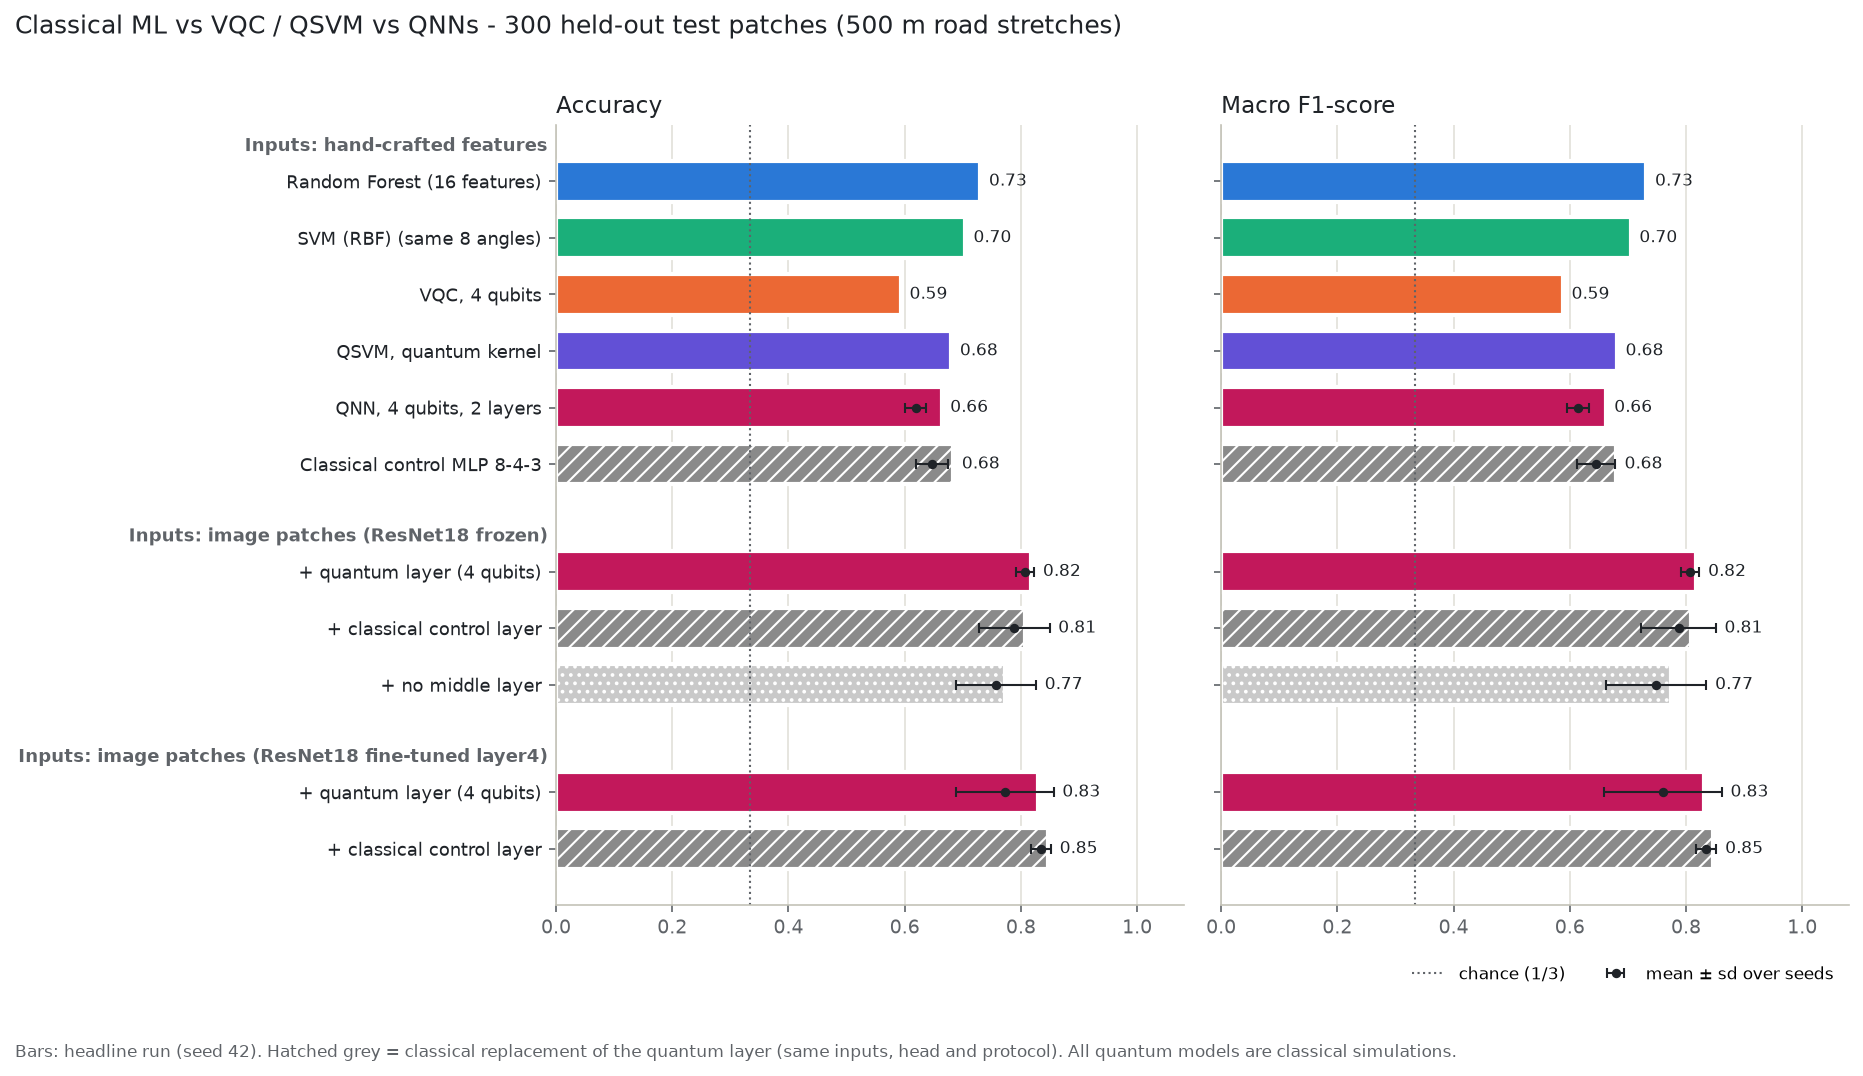

## All models incl. QNNs - unseen-highway split

300 held-out test patches. Single headline run (seed 42) per model; the seed column repeats the training with other initialisations. Hybrid training time excludes the one-off backbone feature caching for the frozen setting; hybrid inference is end-to-end (resize + ResNet18 on GPU + middle layer).

| Inputs | Model | Type | Accuracy | Precision | Recall | F1 | F1 mean ± sd (seeds) | Training time (s) | Inference (ms/sample) |
|---|---|---|---|---|---|---|---|---|---|
| hand-crafted features | Random Forest (16 features) | Classical | 0.613 | 0.643 | 0.613 | 0.575 | — | 0.36 | 0.080 |
| hand-crafted features | SVM (RBF) (same 8 angles) | Classical | 0.497 | 0.547 | 0.497 | 0.454 | — | 0.02 | 0.019 |
| hand-crafted features | VQC, 4 qubits | Quantum (sim.) | 0.497 | 0.383 | 0.497 | 0.415 | — | 136.72 | 0.022 |
| hand-crafted features | QSVM, quantum kernel | Quantum (sim.) | 0.483 | 0.608 | 0.483 | 0.463 | — | 0.05 | 0.039 |
| hand-crafted features | QNN, 4 qubits, 2 layers | Quantum (sim.) | 0.410 | 0.453 | 0.410 | 0.353 | 0.315 ± 0.069 (n=5) | 13.69 | 0.032 |
| hand-crafted features | Classical control MLP 8-4-3 | Classical | 0.493 | 0.402 | 0.493 | 0.412 | 0.356 ± 0.051 (n=5) | 0.18 | 0.000 |
| image patches (ResNet18 frozen) | + quantum layer (4 qubits) | Hybrid quantum (sim.) | 0.720 | 0.755 | 0.720 | 0.701 | 0.750 ± 0.030 (n=5) | 25.11 | 1.805 |
| image patches (ResNet18 frozen) | + classical control layer | Classical | 0.770 | 0.800 | 0.770 | 0.763 | 0.773 ± 0.034 (n=5) | 5.35 | 0.591 |
| image patches (ResNet18 frozen) | + no middle layer | Classical | 0.720 | 0.757 | 0.720 | 0.703 | 0.700 ± 0.083 (n=5) | 1.86 | 1.690 |
| image patches (ResNet18 fine-tuned layer4) | + quantum layer (4 qubits) | Hybrid quantum (sim.) | 0.810 | 0.815 | 0.810 | 0.803 | 0.757 ± 0.058 (n=3) | 87.00 | 1.725 |
| image patches (ResNet18 fine-tuned layer4) | + classical control layer | Classical | 0.817 | 0.836 | 0.817 | 0.818 | 0.827 ± 0.016 (n=3) | 38.86 | 1.705 |


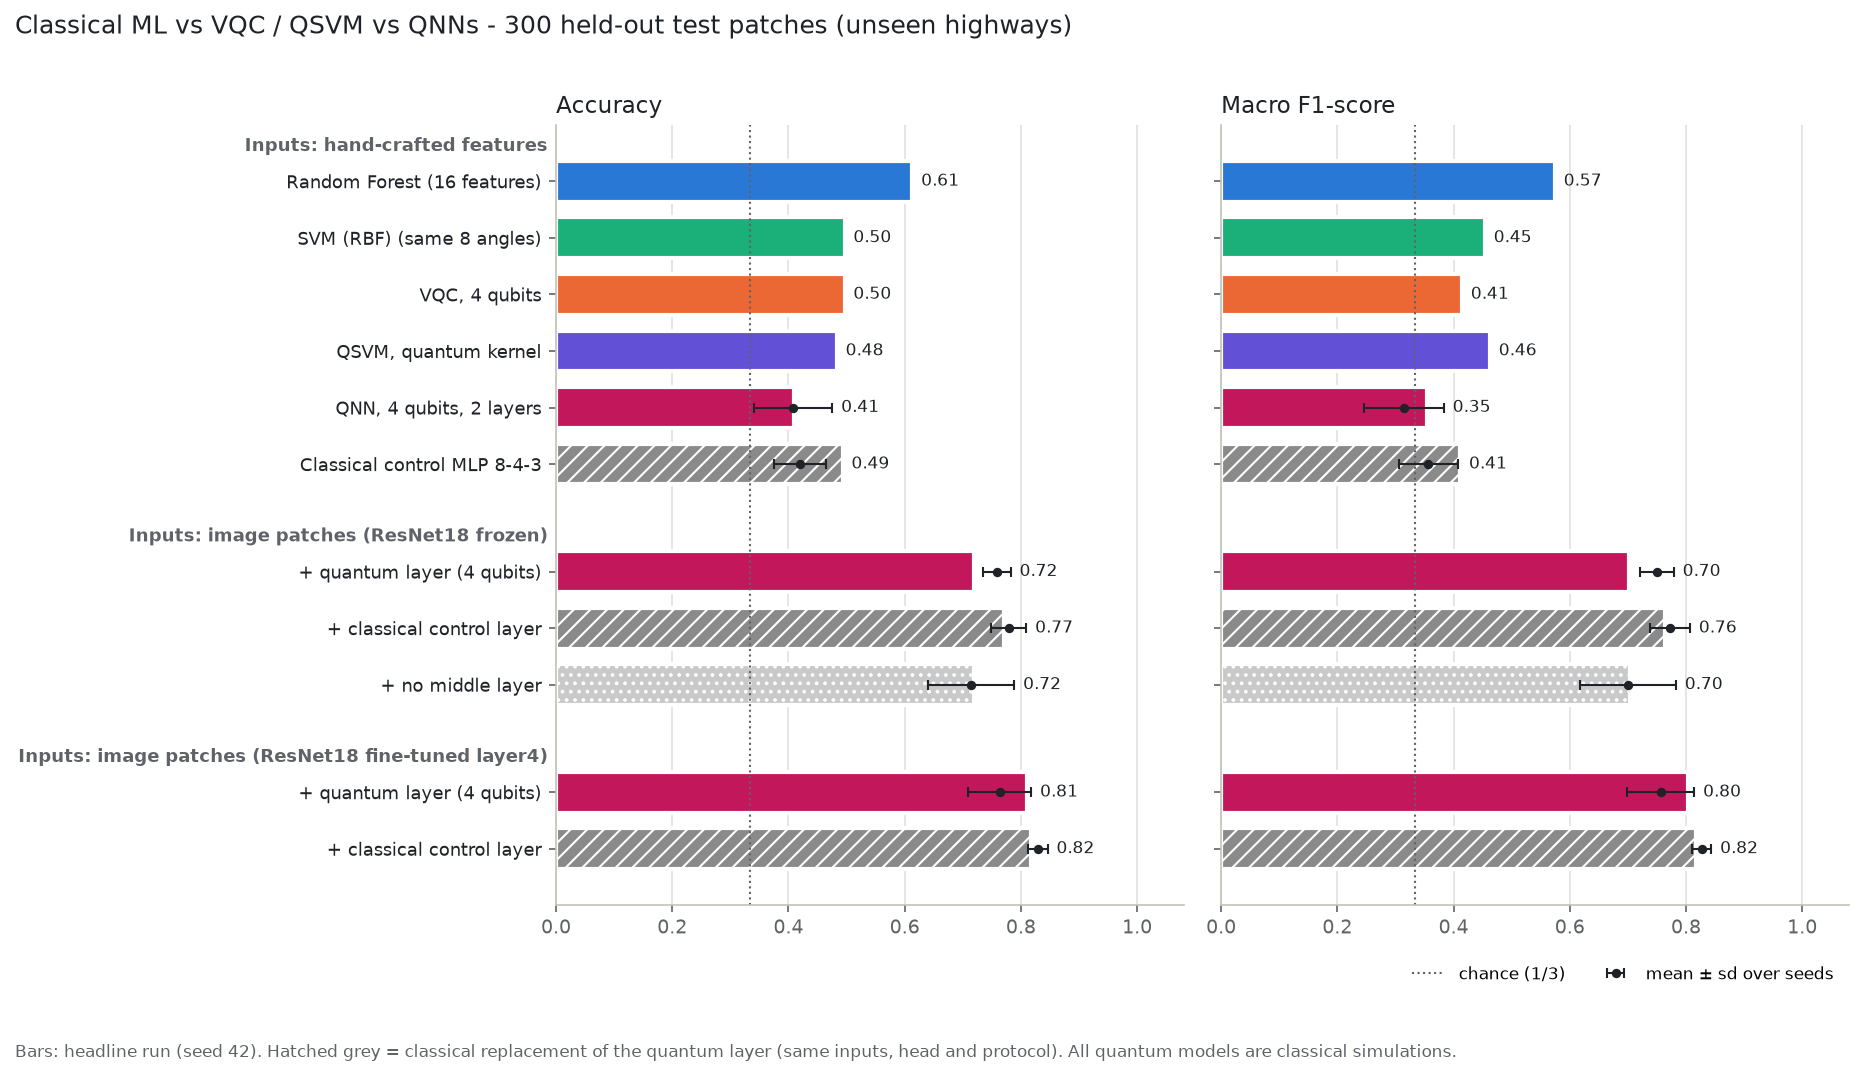

In [10]:
from IPython.display import Markdown
for suf in ('', '_unseen_highway'):
    p = METRICS_DIR / f'comparison_with_qnn{suf}.md'
    if p.exists():
        display(Markdown(p.read_text(encoding='utf-8')))
        display(Image(str(GRAPHS_DIR / f'comparison_with_qnn{suf}.png')))

**Reading:** the feature QNN beats the VQC but not classical ML on the same 8 inputs; the hybrid is much stronger only because of the pretrained CNN, and its classical twin matches or beats it. No quantum advantage. Discussion: `docs/06_qnn.md`.